In [40]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.utils import check_random_state
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
!pip --quiet install torch torchvision torchaudio
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, Dataset
!pip install --quiet transformers[torch] --upgrade
from transformers import BertTokenizer, BertModel
from torch.optim import AdamW
!pip --quiet install tensorflow
from tensorflow import keras
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [41]:
# ✅ Check for GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [42]:
# Mount Google Drive (if the files are in Google Drive)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [43]:
# Define the column names you want to use
col_names = ["conv_id", "utterance_idx", "context", "prompt", "speaker_idx", "utterance"]
# Assuming files are in a folder called "DatasetFiles" in your Drive:
train_file = "/content/drive/MyDrive/DatasetFiles/train.csv"
valid_file = "/content/drive/MyDrive/DatasetFiles/valid.csv"
test_file = "/content/drive/MyDrive/DatasetFiles/test.csv"
# File names
#train_file = "train.csv"
#valid_file = "valid.csv"
#output_file = "merged.csv"

# Read CSV while selecting only these columns (skip actual header)
train_df = pd.read_csv(train_file, usecols=col_names)
valid_df = pd.read_csv(valid_file, usecols=col_names)
test_df = pd.read_csv(test_file, usecols=col_names)
print(np.shape(train_df))
print(np.shape(valid_df))
print(np.shape(test_df))

# Drop rows with missing values in the specified columns
train_df.dropna(subset=col_names, inplace=True)
valid_df.dropna(subset=col_names, inplace=True)
test_df.dropna(subset=col_names, inplace=True)

print(np.shape(train_df))
print(np.shape(valid_df))
print(np.shape(test_df))
# Clean text (replace _comma_ with ,)
for df in [train_df, valid_df, test_df]:
    df["prompt"] = df["prompt"].str.replace("_comma_", ",")
    df["utterance"] = df["utterance"].str.replace("_comma_", ",")
    df["utterance_idx"] = pd.to_numeric(df["utterance_idx"], errors="coerce")
    df["speaker_idx"] = pd.to_numeric(df["speaker_idx"], errors="coerce")

# Group conversations by conv_id
grouped_train = train_df.groupby("conv_id").agg({
    "prompt": "first",
    "utterance": lambda x: " ".join(x),
    "context": "first"
}).reset_index()

grouped_valid = valid_df.groupby("conv_id").agg({
    "prompt": "first",
    "utterance": lambda x: " ".join(x),
    "context": "first"
}).reset_index()

grouped_test = test_df.groupby("conv_id").agg({
    "prompt": "first",
    "utterance": lambda x: " ".join(x),
    "context": "first"
}).reset_index()

# Define input text
grouped_train["input_text"] = "Prompt: " + grouped_train["prompt"] + " Conversation: " + grouped_train["utterance"]
grouped_valid["input_text"] = "Prompt: " + grouped_valid["prompt"] + " Conversation: " + grouped_valid["utterance"]
grouped_test["input_text"] = "Prompt: " + grouped_test["prompt"] + " Conversation: " + grouped_test["utterance"]

# Merge datasets
#merged_df = pd.concat([grouped_train, grouped_valid], ignore_index=True)

# Save the merged dataset to a new CSV file
#merged_df.to_csv(output_file, index=False)

# Print the shape of the merged file
#print(f"Merged CSV saved as {output_file} with shape: {merged_df.shape}")
# Define the emotion group mapping
emotion_mapping = {
    "afraid": "fear", "terrified": "fear", "angry": "anger", "annoyed": "anger",
    "furious": "anger", "anxious": "worried", "apprehensive": "worried", "ashamed": "shame",
    "embarrassed": "shame", "guilty": "shame", "hopeful": "hope", "confident": "hope",
    "prepared": "hope", "sad": "sadness", "devastated": "sadness", "excited": "happy",
    "anticipating": "happy", "joyful": "happy", "impressed": "recognition",
    "proud": "recognition", "nostalgic": "nostalgia",
    "sentimental": "nostalgia"}


# ✅ Define features and labels for train/test split
X_train = grouped_train["input_text"]
y_train = grouped_train["context"]
X_valid = grouped_valid["input_text"]
y_valid = grouped_valid["context"]
X_test = grouped_test["input_text"]
y_test = grouped_test["context"]

# ✅ Apply emotion mapping
y_train = y_train.map(lambda x: emotion_mapping.get(x, x))  # Map with fallback to original
y_valid = y_valid.map(lambda x: emotion_mapping.get(x, x))
y_test = y_test.map(lambda x: emotion_mapping.get(x, x))


# ✅ Encode emotion labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_valid_encoded = label_encoder.transform(y_valid)
y_test_encoded = label_encoder.transform(y_test)

# Save mapping for decoding predictions later
label_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print(label_mapping)
print(len(np.unique(y_train_encoded)))
print(len(np.unique(y_valid_encoded)))
print(len(np.unique(y_test_encoded)))

(76673, 6)
(12030, 6)
(10943, 6)
(76673, 6)
(12030, 6)
(10943, 6)
{'anger': np.int64(0), 'caring': np.int64(1), 'content': np.int64(2), 'disappointed': np.int64(3), 'disgusted': np.int64(4), 'faithful': np.int64(5), 'fear': np.int64(6), 'grateful': np.int64(7), 'happy': np.int64(8), 'hope': np.int64(9), 'jealous': np.int64(10), 'lonely': np.int64(11), 'nostalgia': np.int64(12), 'recognition': np.int64(13), 'sadness': np.int64(14), 'shame': np.int64(15), 'surprised': np.int64(16), 'trusting': np.int64(17), 'worried': np.int64(18)}
19
19
19


<ipython-input-44-cc95b1886c15>:62: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
<ipython-input-44-cc95b1886c15>:35: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():  # Enable Mixed Precision Training


Epoch 1: Train Loss = 1.2783, Train Acc = 0.6292, Valid Loss = 0.9101, Valid Acc = 0.7286
🔻 Learning rate adjusted to 0.00001819
✅ Best model saved!
Epoch 2: Train Loss = 0.6764, Train Acc = 0.8044, Valid Loss = 0.8357, Valid Acc = 0.7535
🔻 Learning rate adjusted to 0.00001344
✅ Best model saved!
Epoch 3: Train Loss = 0.4235, Train Acc = 0.8781, Valid Loss = 0.8952, Valid Acc = 0.7535
🔻 Learning rate adjusted to 0.00000756
Epoch 4: Train Loss = 0.2574, Train Acc = 0.9341, Valid Loss = 0.9402, Valid Acc = 0.7546
🔻 Learning rate adjusted to 0.00000281
Epoch 5: Train Loss = 0.1666, Train Acc = 0.9606, Valid Loss = 0.9797, Valid Acc = 0.7539
🔻 Learning rate adjusted to 0.00000100


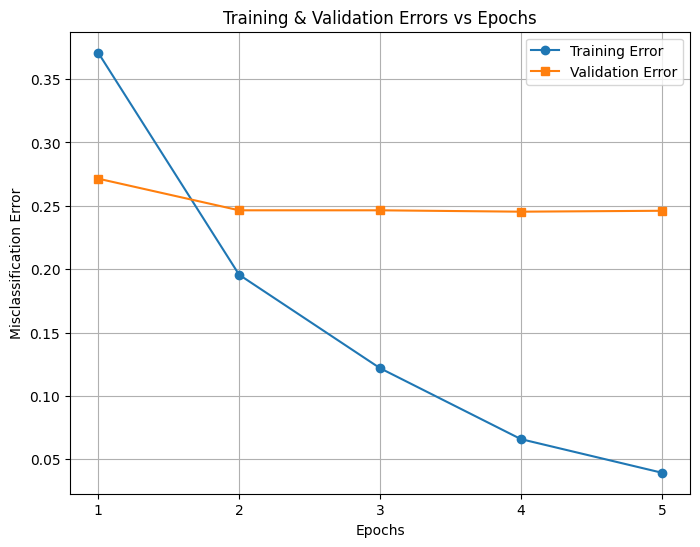

In [44]:

# ✅ Load pre-trained BERT tokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

# ✅ Custom Dataset Class
class EmotionDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts.tolist()
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded_text = tokenizer(self.texts[idx],
                                 truncation=True,
                                 padding="max_length",
                                 max_length=128,
                                 return_tensors="pt")

        return {
            "input_ids": encoded_text["input_ids"].squeeze(0),
            "attention_mask": encoded_text["attention_mask"].squeeze(0),
            "label": self.labels[idx]
        }

# ✅ Define Model (BERT with [CLS] Token for Classification)
class BertEmotionClassifier(nn.Module):
    def __init__(self, num_classes):
        super(BertEmotionClassifier, self).__init__()
        self.bert = BertModel.from_pretrained("bert-base-uncased")
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(self.bert.config.hidden_size, num_classes)  # Use [CLS] embedding

    def forward(self, input_ids, attention_mask):
        with torch.cuda.amp.autocast():  # Enable Mixed Precision Training
            outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
            cls_embedding = outputs.last_hidden_state[:, 0, :]  # Extract [CLS] token embedding
            x = self.dropout(cls_embedding)
            x = self.fc(x)
        return x

# ✅ Create Dataset Objects
train_dataset = EmotionDataset(X_train, y_train_encoded)
valid_dataset = EmotionDataset(X_valid, y_valid_encoded)

# ✅ DataLoader
batch_size = 16
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)

# ✅ Initialize Model
num_classes = len(label_mapping)  # Number of unique emotion classes
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = BertEmotionClassifier(num_classes).to(device)

# ✅ Define Loss Function & Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=2e-5, eps=1e-8,weight_decay=0.01)


# ✅ Mixed Precision Training (FP16) - Gradient Scaler
scaler = torch.cuda.amp.GradScaler()

# ✅ Gradient Accumulation Steps
accumulation_steps = 4  # Adjust based on memory constraints

# ✅ Define the Cosine Annealing LR Scheduler
from torch.optim.lr_scheduler import CosineAnnealingLR
T_max = 5  # Number of epochs before restarting (adjustable)
scheduler = CosineAnnealingLR(optimizer, T_max=T_max, eta_min=1e-6)  # Minimum LR = 1e-6


# ✅ Updated Training Function
def train_model(model, train_loader, valid_loader, epochs=5):
    best_valid_loss = float("inf")
    train_err, valid_err = [], []  # Store errors for plotting
    for epoch in range(epochs):
        model.train()
        total_loss, total_correct = 0, 0

        for batch in train_loader:
            input_ids, attention_mask, labels = (
                batch["input_ids"].to(device),
                batch["attention_mask"].to(device),
                batch["label"].to(device),
            )

            optimizer.zero_grad()
            outputs = model(input_ids, attention_mask)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            total_correct += (outputs.argmax(dim=1) == labels).sum().item()

        avg_train_loss = total_loss / len(train_loader)
        train_acc = total_correct / len(train_dataset)
        train_err.append(1-train_acc)
        # ✅ Validation
        model.eval()
        valid_loss, valid_correct = 0, 0
        with torch.no_grad():
            for batch in valid_loader:
                input_ids, attention_mask, labels = (
                    batch["input_ids"].to(device),
                    batch["attention_mask"].to(device),
                    batch["label"].to(device),
                )
                outputs = model(input_ids, attention_mask)
                loss = criterion(outputs, labels)

                valid_loss += loss.item()
                valid_correct += (outputs.argmax(dim=1) == labels).sum().item()

        avg_valid_loss = valid_loss / len(valid_loader)
        valid_acc = valid_correct / len(valid_dataset)
        valid_err.append(1-valid_acc)
        print(
            f"Epoch {epoch+1}: Train Loss = {avg_train_loss:.4f}, Train Acc = {train_acc:.4f}, "
            f"Valid Loss = {avg_valid_loss:.4f}, Valid Acc = {valid_acc:.4f}"
        )

        # ✅ Apply the Cosine Annealing Scheduler
        scheduler.step()
        print(f"🔻 Learning rate adjusted to {scheduler.get_last_lr()[0]:.8f}")

        # ✅ Save best model
        if avg_valid_loss < best_valid_loss:
            best_valid_loss = avg_valid_loss
            torch.save(model.state_dict(), "bert_emotion_classifier_best.pth")
            print("✅ Best model saved!")

    # ✅ Plot Training & Validation Accuracy
    plt.figure(figsize=(8, 6))
    plt.plot(range(1, epochs+1), train_err, label="Training Error", marker="o")
    plt.plot(range(1, epochs+1), valid_err, label="Validation Error", marker="s")
    plt.xlabel("Epochs")
    plt.ylabel("Misclassification Error")
    plt.title("Training & Validation Errors vs Epochs")
    plt.legend()
    plt.grid(True)
    plt.xticks(list(range(1, epochs+1)))  # Ensures only 1, 2, 3, 4, 5 appear
    plt.savefig('Training & Validation Errors vs Epochs.pdf', bbox_inches='tight')  # Save the plot as a PDF
    plt.show()

# ✅ Train the model with Cosine Annealing
train_model(model, train_loader, valid_loader, epochs=5)

<ipython-input-44-cc95b1886c15>:35: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():  # Enable Mixed Precision Training


Test Loss = 0.8722, Test Accuracy = 0.7459
              precision    recall  f1-score   support

       anger       0.82      0.75      0.78       242
      caring       0.63      0.84      0.72        80
     content       0.80      0.67      0.73        76
disappointed       0.62      0.49      0.55        81
   disgusted       0.75      0.88      0.81        86
    faithful       0.85      0.58      0.69        50
        fear       0.69      0.81      0.74       144
    grateful       0.72      0.53      0.61        95
       happy       0.74      0.67      0.70       247
        hope       0.74      0.77      0.76       231
     jealous       0.78      0.75      0.77        81
      lonely       0.84      0.87      0.86        78
   nostalgia       0.87      0.82      0.85       168
 recognition       0.65      0.89      0.75       177
     sadness       0.72      0.77      0.74       155
       shame       0.86      0.80      0.83       211
   surprised       0.73      0.65     

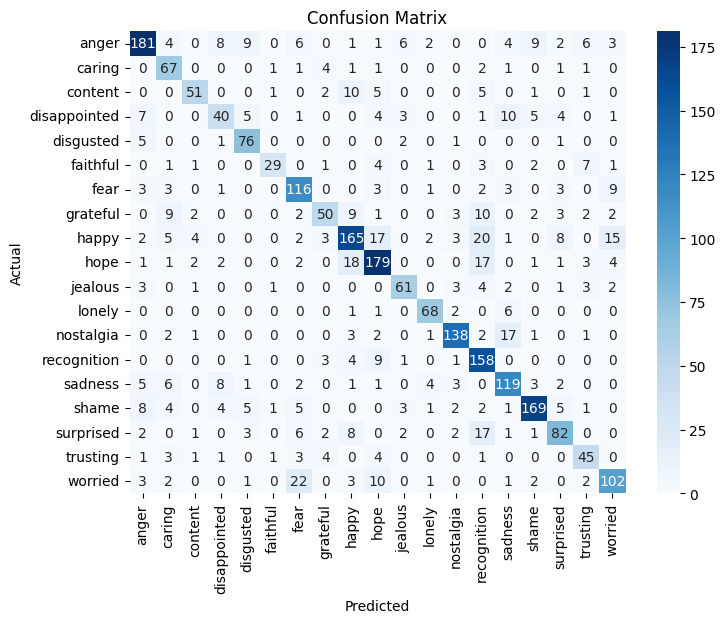

In [45]:
# ✅ Step 1: Create Test Dataset & DataLoader
test_dataset = EmotionDataset(X_test, y_test_encoded)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# ✅ Step 2: Define the Test Function
def evaluate_model(model, test_loader):
    model.eval()  # Set model to evaluation mode
    total_loss, total_correct = 0, 0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for batch in test_loader:
            input_ids, attention_mask, labels = (
                batch["input_ids"].to(device),
                batch["attention_mask"].to(device),
                batch["label"].to(device),
            )

            # Forward pass
            outputs = model(input_ids, attention_mask)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            preds = outputs.argmax(dim=1)  # Get predicted labels
            total_correct += (preds == labels).sum().item()

            # Store results for further analysis
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Compute test accuracy
    avg_test_loss = total_loss / len(test_loader)
    test_acc = total_correct / len(test_dataset)
    print(f"Test Loss = {avg_test_loss:.4f}, Test Accuracy = {test_acc:.4f}")

    return all_preds, all_labels

# ✅ Step 3: Load Best Trained Model (BEFORE Evaluation)
model.load_state_dict(torch.load("bert_emotion_classifier_best.pth"))
model.to(device)

# ✅ Step 4: Evaluate the Model
test_preds, test_labels = evaluate_model(model, test_loader)

# ✅ Step 5 Classification Report & Confusion Matrix


# Convert classification report to a dictionary
report_dict = classification_report(test_labels, test_preds, target_names=label_mapping.keys(), output_dict=True)

# Convert to DataFrame and save as CSV
df = pd.DataFrame(report_dict).transpose()
df.to_csv("classification_report_test_set.csv", index=True)
print(classification_report(test_labels, test_preds, target_names=label_mapping.keys()))

# Plot Confusion Matrix
conf_matrix = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=label_mapping.keys(), yticklabels=label_mapping.keys())
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.savefig('Test Set Confusion Matrix.jpg', bbox_inches='tight')  # Save the plot as a PDF
plt.show()


In [46]:
# Reverse the label mapping (integer -> string)
reverse_label_mapping = {v: k for k, v in label_mapping.items()}
# Define a safe way to access the reversed label mapping
def get_label_name(label):
    # Return the label if it exists in the reversed mapping, else return the label itself
    return reverse_label_mapping.get(label, str(label))

# ✅ Step 6: Print Misclassified Examples
misclassified_examples = []

# Iterate through predictions to find misclassified samples
for text, true, pred in zip(X_test, test_labels, test_preds):
    if true != pred:  # Check if the example is misclassified
        misclassified_examples.append((text, true, pred))

# Display first 5 misclassified examples
print("\nMisclassified Examples:")
for i, (text, true, pred) in enumerate(misclassified_examples[:5]):  # Print first 5 misclassified
    print(f"Example {i+1}:")
    print(f"Text: {text}")
    print(f"True Label: {get_label_name(true)}")  # Use the get_label_name function
    print(f"Predicted Label: {get_label_name(pred)}")  # Use the get_label_name function
    print("-" * 50)



Misclassified Examples:
Example 1:
Text: Prompt: I have problems with the city and their constant tax increase on my property. Conversation: I have problems with the city and their constant tax increase on my property. I know how you feel, it's terrible. I actually moved to a completely different state due to hi taxes. Maybe A move out of my state would be the answer and a blessing to the high taxes.  It's worth it to consider. I pay less than half in property tax than I used to.
True Label: trusting
Predicted Label: anger
--------------------------------------------------
Example 2:
Text: Prompt: I really enjoy watching videos on YouTube. I feel the content is really good. Conversation: Do you watch any YouTube at all? I watch everyday. love youtube! What type of content do you like watching? I like self help, motivation, healthy living, and a little bit of conspiracy.
True Label: content
Predicted Label: hope
--------------------------------------------------
Example 3:
Text: Prompt

In [47]:
reverse_label_mapping = {v: k for k, v in label_mapping.items()}  # Create reverse mapping

# Convert encoded labels back to text labels
test_labels = [reverse_label_mapping[label] for label in y_test_encoded]

# Get the percentage distribution of the original text labels
label_distribution = pd.Series(test_labels).value_counts(normalize=True) * 100

# Define a safe way to access the reversed label mapping
def get_label_name(label):
    return reverse_label_mapping.get(label, str(label))

# Convert to DataFrame for better formatting
df_distribution = label_distribution.reset_index()
df_distribution.columns = ["Label", "Percentage"]  # Use correct column names

# Display the full percentage distribution
print(df_distribution)

# Save as CSV (optional)
# df_distribution.to_csv("test_set_label_distribution.csv", index=False)


           Label  Percentage
0          happy    9.716758
1          anger    9.520063
2           hope    9.087333
3          shame    8.300551
4    recognition    6.963021
5      nostalgia    6.608969
6        sadness    6.097561
7        worried    5.861526
8           fear    5.664831
9      surprised    4.996066
10      grateful    3.737215
11     disgusted    3.383163
12  disappointed    3.186467
13       jealous    3.186467
14        caring    3.147128
15        lonely    3.068450
16       content    2.989772
17      trusting    2.517703
18      faithful    1.966955
